# MECHA in metafspm, 4: a whole plant in its soil

The previous tutorials solved one root section, then one needle. Here, the same components on a whole seedling in a
soil column, as metafspm's soil–plant–atmosphere example (`metafspm/examples/soil_plant_atmosphere`), with GRANAP's
anatomies and MECHA's hydraulics in the plant: water from the water table through the soil, into every root
section's cells and walls, up the xylem of the roots, the stem and the leaves, and out through the stomata.

The pieces, all from `example/soil_plant_atmosphere/seedling_spac.py`:

| piece | what it is | role it plays |
|---|---|---|
| `SeedlingArchitecture` | the seedling's segments: 3 phytomers (stem, leaf of 3 elements), 3 root axes with laterals | architecture |
| `SeedlingAnatomy` | GRANAP's component: roots by the root preset (by diameter), stems and leaves by the monocot presets | anatomy |
| `development` | a stand-in for a root development model: the barriers by distance from the tip | development |
| `MechaOsmoticPresets` | MECHA's osmotic presets, standing for a solute model | solutes |
| `leaf_transpiration` | each leaf organ's share of the plant's transpiration (a constant for now) | transpiration |
| `MechaHydraulics` | MECHA's component: the plant problem on every section of the plant | hydraulics |
| `SeedlingHydraulics` | the `CompositeModel` assembling them, one step per call | the plant model |
| `Soil` | metafspm's soil model (a 3D grid, Richards' equation) | environment |
| `Scene` | the plants and the soil, their exchanges at each step | the simulation |

In [1]:
import os
import sys
import time
import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

HERE = os.path.abspath("")
sys.path.insert(0, os.path.join(HERE, "..", "soil_plant_atmosphere"))
import seedling_spac                                                  # noqa: E402
import plots as spac_plots                                            # noqa: E402
from openalea.metafspm.scene.scene import Scene                       # noqa: E402

## 1. The plant model: a `CompositeModel`

Its class attributes tell the Scene how to build the population (the initiators, in order: the architecture, then
GRANAP's anatomies; the DataStructure's nodes, the Compartments, and its wiring, GRANAP's junction rules); its
`__init__` instantiates the components on the DataStructure and couples them; `run` is one time step. Read it:

In [2]:
print(inspect.getsource(seedling_spac.SeedlingHydraulics))

class SeedlingHydraulics(CompositeModel):
    """
    The plant population model: the seedlings' architecture (initiators), their GRANAP anatomies (anatomy mode: the
    Compartments are the graph's nodes, the vessels joined between sections by GRANAP's junction rules), and MECHA's
    hydraulics on them, from the soil around the roots to the air at the leaves' stomata.
    """
    initiators = (SeedlingArchitecture, SeedlingAnatomy)
    from_scale = "SubOrgan"
    nodes = "Compartment"
    wiring = junction_rules

    def __init__(self, data_structure, time_step):
        self.architecture = SeedlingArchitecture(data_structure=data_structure, time_step=time_step)
        self.anatomy = SeedlingAnatomy(data_structure=data_structure, time_step=time_step)
        self.anatomy()                                                 # the 3D quantities
        if not data_structure.has("barrier"):
            data_structure.register("barrier", np.ones(data_structure.n_nodes()), location="node")


Three things to notice:

- **the components never call each other**: each reads its inputs from the DataStructure and writes its outputs
  there; `run` only orders them (anatomy, development, solutes, hydraulics);
- **the organ-scale input** `leaf_transpiration` is set on each leaf organ before MECHA is built (the third
  tutorial explains how it reaches the stomata);
- **the collar** has no condition (`collar_condition = 0`): the shoot is above the roots, and the transpiration at
  the leaves drives the flow; the root surface is a mask (`root_surface`) the soil mapping uses.

## 2. The scene: the plant, the soil and their exchanges

The soil and the plant speak different units and names. The `Translator` links them: the soil's `water_potential`
(MPa) is MECHA's `soil_psi` (hPa); MECHA's `root_uptake` (cm³ d⁻¹, per border node) is the soil's `plant_uptake`
(mm³ s⁻¹, per voxel). The `CrossMapping` maps the roots' border nodes onto the soil voxels they overlap. The scene
steps the plant and the soil one after the other, each with the other's last values, until the water potentials
stop changing (`largest_change`: a lagged fixed point).

In [3]:
for receiver, provider in (("MechaHydraulics", "SoilWaterTransport"), ("SoilWaterTransport", "MechaHydraulics")):
    for link in seedling_spac.SCENE_TRANSLATOR.links_of(receiver, provider):
        print(f"{link.receiver}.{link.variable} = " + " + ".join(f"{factor:g} × {link.provider}.{name}"
                                                                 for name, factor in link.sources.items()))
print(f"the plant's transpiration: {seedling_spac.TRANSPIRATION} mm³ s⁻¹, split between its leaf organs")

table = pd.DataFrame([dict(plant="seedling", model=seedling_spac.SeedlingHydraulics, x=0.1, y=0.1, z=0., rotation=0.,
                           scenario={"parameters": {}})])
table.attrs.update(xrange=0.2, yrange=0.2)                            # a 0.2 m x 0.2 m column of soil
stop = seedling_spac.largest_change(1e-4)
start = time.perf_counter()
scene = Scene(table, environment=[seedling_spac.Soil], environment_scenarios=[{}],
              translator=seedling_spac.SCENE_TRANSLATOR, time_step=3600,
              mappings=seedling_spac.root_surface_mappings, stop_when=stop)
print(f"built in {time.perf_counter() - start:.0f} s")

MechaHydraulics.soil_psi = 10000 × SoilWaterTransport.water_potential
SoilWaterTransport.plant_uptake = 0.0115741 × MechaHydraulics.root_uptake
the plant's transpiration: 0.15 mm³ s⁻¹, split between its leaf organs


built in 39 s


In [4]:
plant = scene.populations[0].data_structure
g = plant.mtg
labels = g.property("label")
kinds = pd.Series([next(name for name in ("RootSegment", "StemElement", "LeafElement")
                        if labels[int(v)] == getattr(g.labels.SubOrgan, name)) for v in plant.entity_ids("SubOrgan")])
anatomy = scene.populations[0].instance.anatomy                  # the model instance the Scene built
n_templates = sum(len(organ.library.templates) for organ in anatomy.organs().values())
print(f"{len(kinds)} sections ({kinds.value_counts().to_dict()}), {n_templates} anatomy templates; "
      f"{plant.n_nodes()} Compartments, {plant.n_edges()} Connections")

48 sections ({'RootSegment': 36, 'LeafElement': 9, 'StemElement': 3}), 4 anatomy templates; 523509 Compartments, 1291965 Connections


## 3. Run to the fixed point

In [5]:
start = time.perf_counter()
scene.simulate(30)
print(f"simulated in {time.perf_counter() - start:.0f} s; {scene.iteration} steps; largest change of Ψ per step (MPa):",
      ", ".join(f"{change:.1e}" for change in stop.history))
soil = next(model for model in scene.environment if isinstance(model, seedling_spac.Soil)).grid
to_mm3_s = seedling_spac.CM3_PER_DAY_TO_MM3_PER_S
pd.Series({"transpiration (mm³ s⁻¹)": plant.get("evaporation").sum() * to_mm3_s,
           "root uptake (mm³ s⁻¹)": plant.get("root_uptake").sum() * to_mm3_s,
           "taken from the soil (mm³ s⁻¹)": soil.get("plant_uptake").sum(),
           "lowest liquid ψ (MPa)": plant.get("water_potential")[plant.get("vapour_node") == 0].min() / 1e4})

simulated in 78 s; 6 steps; largest change of Ψ per step (MPa): inf, 2.3e+00, 2.2e-02, 1.9e-03, 1.7e-04, 1.6e-05


transpiration (mm³ s⁻¹)          0.150000
root uptake (mm³ s⁻¹)            0.150000
taken from the soil (mm³ s⁻¹)    0.150000
lowest liquid ψ (MPa)           -3.761535
dtype: float64

## 4. The results

The example's figures, written by `example/soil_plant_atmosphere/plots.py`: the plant over the soil's potential;
a section of each organ; the potential along the water's path; the roots' kr; and the potentials upscaled from the
Compartments to the sections, organs, axes and plant (metafspm's cross-scale mappings).

In [6]:
folder = os.path.join(HERE, "outputs", "tutorial_04")
spac_plots.all_figures(scene, folder)

ψ upscaled (MPa): Compartment 523509 [-199.43, -1.78], SubOrgan 48 [-3.50, -1.81], Organ 13 [-3.50, -2.40], Phytomer 6 [-3.44, -2.50], GrowthUnit 4 [-3.44, -2.50], Axis 4 [-3.44, -2.50], Plant 1 [-2.80, -2.80]


ψ by tissue (MPa; organ, tissue, nodes, mean, min):


  root  air space                      10643  -2.273  -2.515
  root  cortex                          5974  -2.293  -2.536
  root  endodermis                       928  -2.908  -3.000
  root  epidermis                       4872  -2.204  -2.326
  root  exodermis                       2291  -2.209  -2.332
  root  metaxylem                        145  -3.487  -3.497
  root  pericycle                       2813  -3.463  -3.598
  root  phloem                           290  -3.477  -3.549
  root  protoxylem                       290  -3.477  -3.630
  root  stele                          11774  -3.480  -3.609
  root  apoplast (walls, junctions)   199781  -2.698  -3.628
  stem  air space                       1647  -3.402  -3.549
  stem  companion cell                   477  -3.382  -3.569
  stem  cortex                          1365  -3.403  -3.560
  stem  epidermis                        783  -3.405  -3.494
  stem  parenchyma                     11490  -3.380  -3.577
  stem  sclerenchyma    

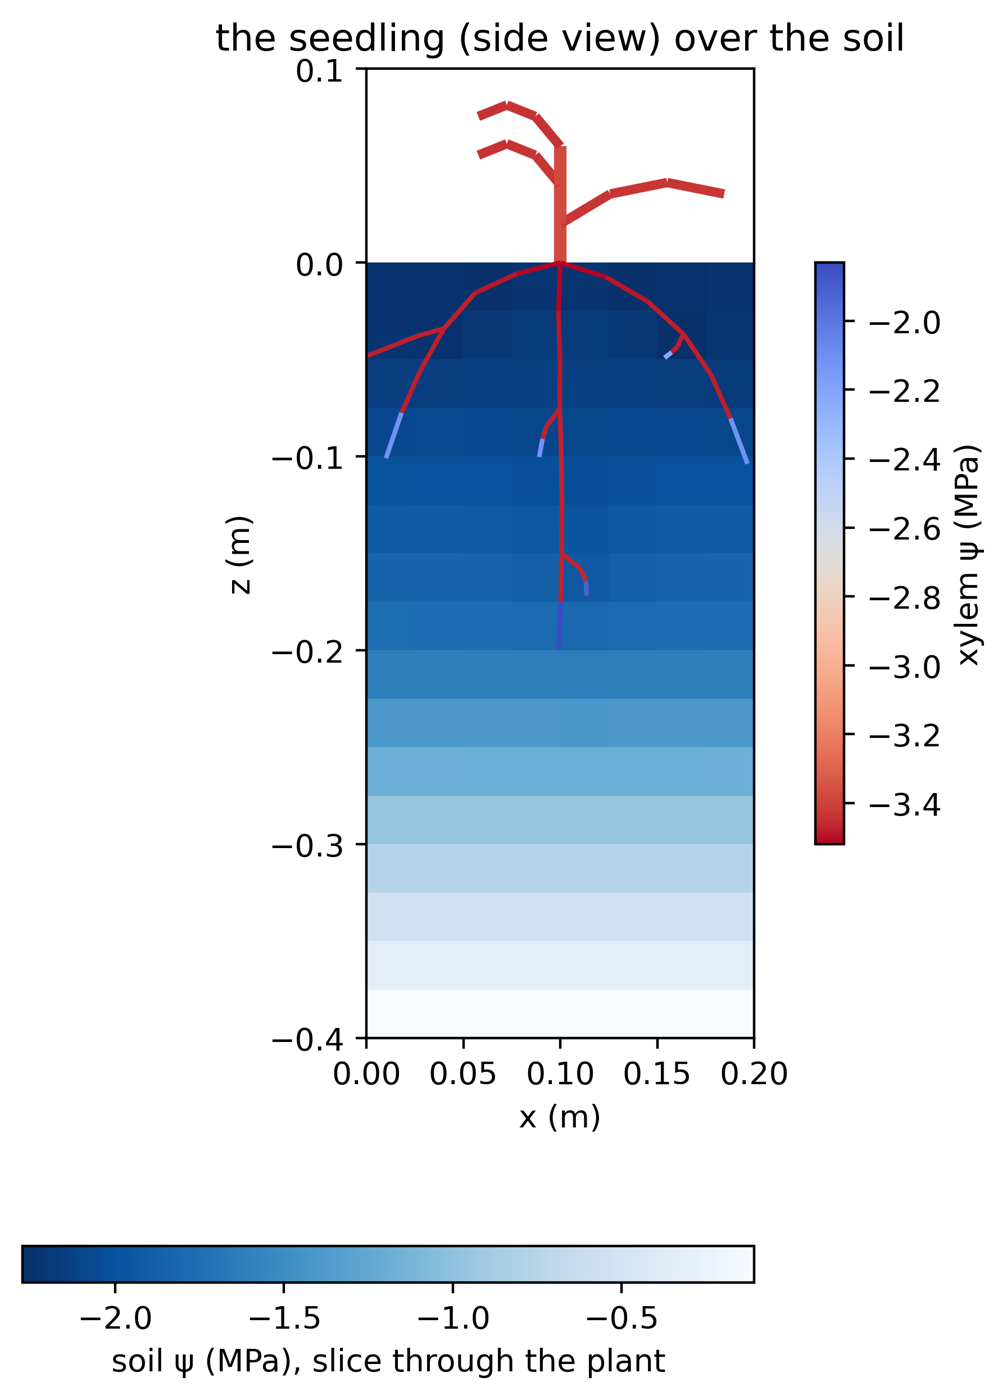

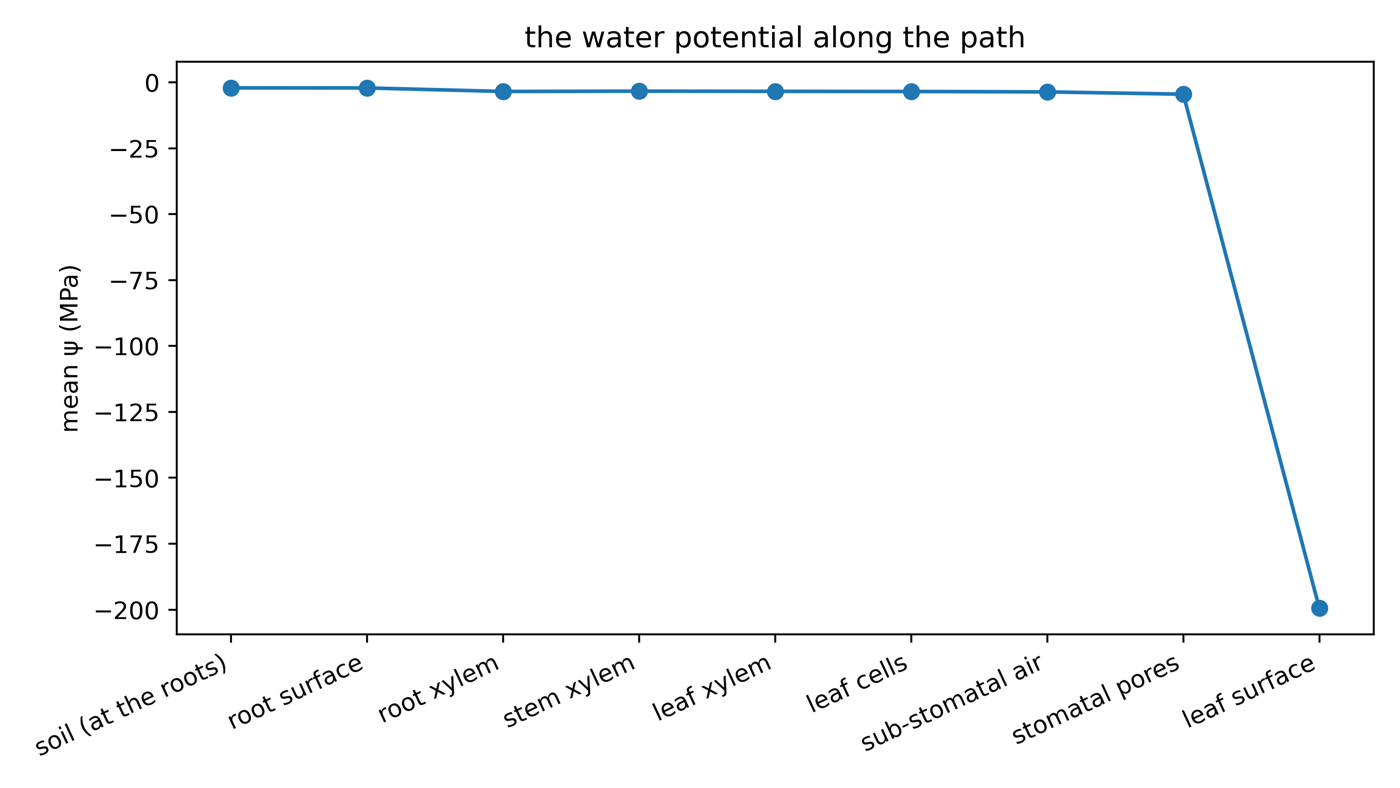

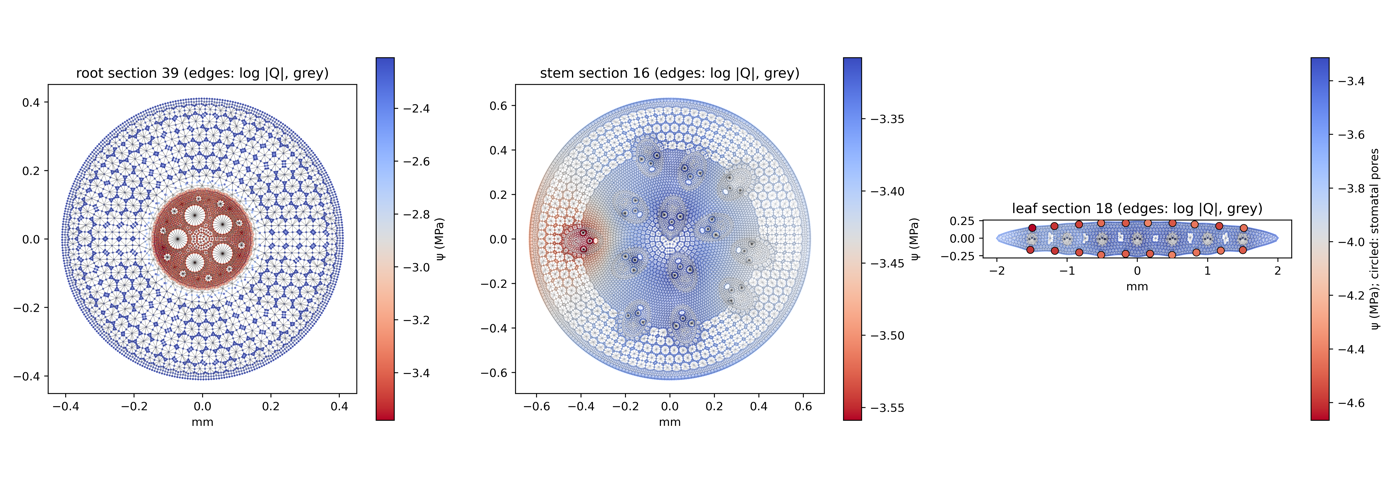

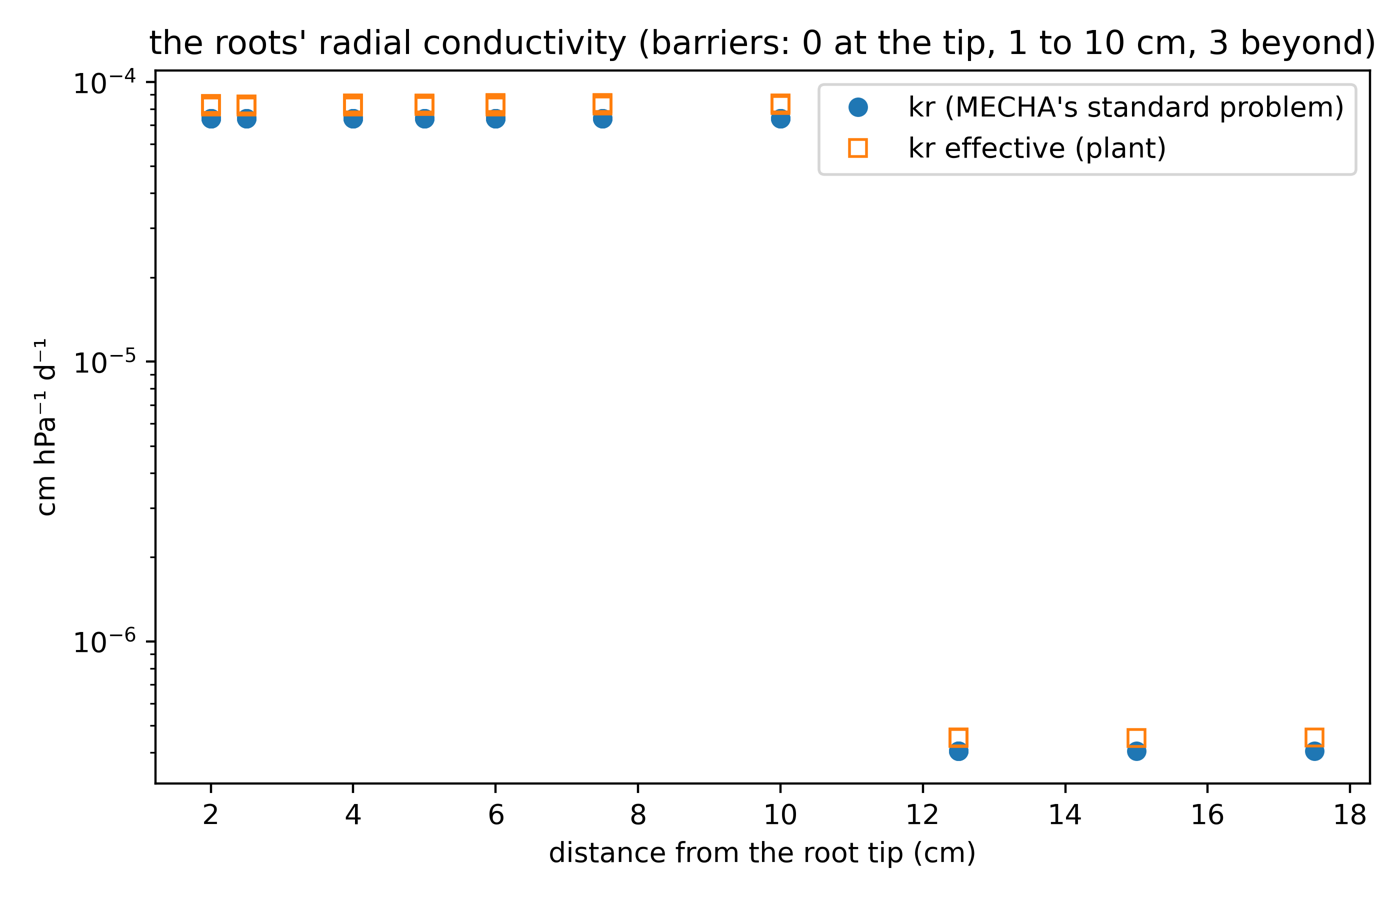

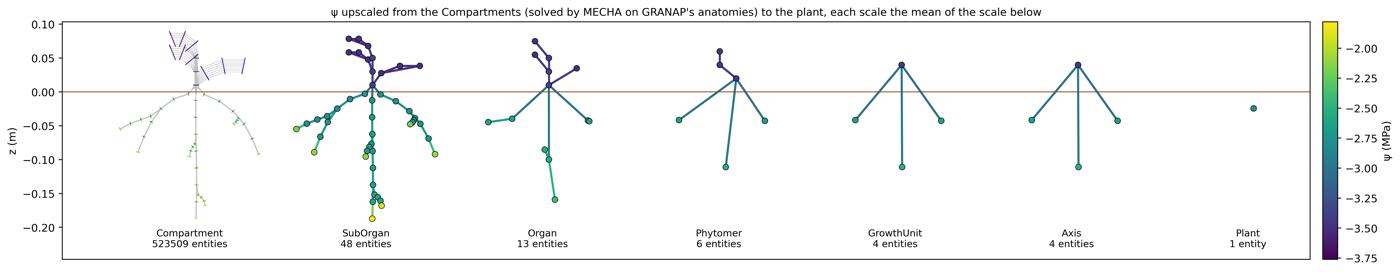

In [7]:
import io
from PIL import Image as PILImage

for name in ("plant_over_soil", "potential_profile", "sections_by_organ", "root_kr", "upscaling"):
    picture = PILImage.open(os.path.join(folder, f"{name}.png"))
    picture.thumbnail((1400, 1400))                                   # the files are 300 dpi
    buffer = io.BytesIO()
    picture.save(buffer, format="png", optimize=True)
    display(Image(data=buffer.getvalue(), width=900))

## What to take away

- The plant model is a composition: GRANAP's anatomies, MECHA's hydraulics, a development stand-in, osmotic
  presets standing for a solute model. Each piece is replaceable by another model providing the same variables
  (a root growth model, MechaSolutes, a transpiration model).
- The soil is another metafspm model; the Scene handles their exchanges, the units and the spatial mapping.
- MECHA's legacy solves one section from an XML file. Here every section of every organ is solved together, from
  the anatomies of a growing plant, coupled to its soil.